*Link das imagens:* https://drive.google.com/drive/folders/1rjNjzxA1B0NhdsFSku-zCr9I39yFLhkQ?usp=sharing

✅ Modelo MediaPipe (.task) baixado com sucesso!
✅ Posição corporal identificada com sucesso!
📐 Ângulo do Cotovelo Direito: 173.7°


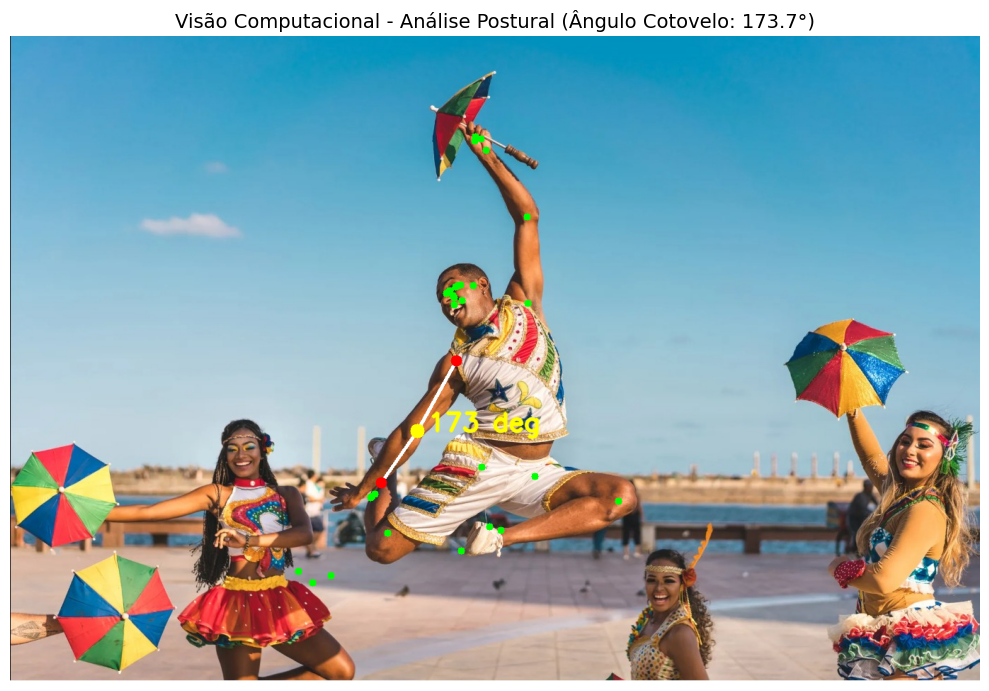

In [9]:
# ==============================================================================
# MINICURSO: Visão Computacional na Prática: Análise de Postura e Movimento com IA e Python
# FATEC Ourinhos
# ==============================================================================

# 1. Instalação do MediaPipe e dependências no Google Colab
!pip install -q mediapipe opencv-python matplotlib urllib3

import cv2
import urllib.request
import numpy as np
import matplotlib.pyplot as plt
import mediapipe as mp

# ==============================================================================
# 2. Download do Modelo Oficial do MediaPipe Pose (.task)
# ==============================================================================
url_modelo = "https://storage.googleapis.com/mediapipe-models/pose_landmarker/pose_landmarker_heavy/float16/latest/pose_landmarker_heavy.task"
caminho_modelo = "pose_landmarker.task"

try:
    urllib.request.urlretrieve(url_modelo, caminho_modelo)
    print("✅ Modelo MediaPipe (.task) baixado com sucesso!")
except Exception as e:
    print(f"⚠️ Erro ao baixar o modelo: {e}")

# ==============================================================================
# 3. Função Matemática para Cálculo do Ângulo (em graus)
# ==============================================================================
def calcular_angulo(a, b, c):
    """
    Calcula o ângulo interno (em graus) formado por três pontos A, B e C,
    onde B é o vértice da articulação.
    """
    a = np.array(a)  # Ponto inicial
    b = np.array(b)  # Vértice (Articulação)
    c = np.array(c)  # Ponto final

    radians = np.arctan2(c[1] - b[1], c[0] - b[0]) - np.arctan2(a[1] - b[1], a[0] - b[0])
    angulo = np.abs(radians * 180.0 / np.pi)

    if angulo > 180.0:
        angulo = 360.0 - angulo

    return angulo

# ==============================================================================
# 4. Leitura da Imagem Local e Inferência com MediaPipe Tasks
# ==============================================================================
# Altere para 'imagem_teste.jpg', 'imagem_teste2.jpg' ou 'imagem_teste3.jpg'
caminho_imagem = "/imagem_teste.jpg"

imagem_bgr = cv2.imread(caminho_imagem)

if imagem_bgr is None:
    print(f"⚠️ AVISO: O arquivo '{caminho_imagem}' não foi encontrado!")
    print("👉 Por favor, envie a imagem para a aba de arquivos na lateral esquerda (ícone 📁).")
else:
    # Conversão de BGR para RGB e criação da estrutura mp.Image
    imagem_rgb = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=imagem_rgb)
    h, w, _ = imagem_rgb.shape
    imagem_anotada = imagem_rgb.copy()

    # Configuração das opções do modelo de Pose
    BaseOptions = mp.tasks.BaseOptions
    PoseLandmarker = mp.tasks.vision.PoseLandmarker
    PoseLandmarkerOptions = mp.tasks.vision.PoseLandmarkerOptions
    VisionRunningMode = mp.tasks.vision.RunningMode

    options = PoseLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=caminho_modelo),
        running_mode=VisionRunningMode.IMAGE
    )

    # Execução da detecção de keypoints
    with PoseLandmarker.create_from_options(options) as landmarker:
        resultado = landmarker.detect(mp_image)

        if resultado.pose_landmarks:
            print("✅ Posição corporal identificada com sucesso!")

            # Pegamos os pontos da primeira pessoa identificada na imagem
            landmarks = resultado.pose_landmarks[0]

            # Mapeamento dos índices anatômicos (MediaPipe Pose Landmarker)
            # 12: Ombro Direito | 14: Cotovelo Direito | 16: Pulso Direito
            ombro = [landmarks[12].x * w, landmarks[12].y * h]
            cotovelo = [landmarks[14].x * w, landmarks[14].y * h]
            pulso = [landmarks[16].x * w, landmarks[16].y * h]

            # Desenhar todas as 33 conexões e pontos no corpo
            for lm in landmarks:
                cx, cy = int(lm.x * w), int(lm.y * h)
                cv2.circle(imagem_anotada, (cx, cy), 5, (0, 255, 0), -1)

            # Destacar as conexões do braço direito
            cv2.line(imagem_anotada, (int(ombro[0]), int(ombro[1])), (int(cotovelo[0]), int(cotovelo[1])), (255, 255, 255), 4)
            cv2.line(imagem_anotada, (int(cotovelo[0]), int(cotovelo[1])), (int(pulso[0]), int(pulso[1])), (255, 255, 255), 4)

            cv2.circle(imagem_anotada, (int(ombro[0]), int(ombro[1])), 8, (255, 0, 0), -1)
            cv2.circle(imagem_anotada, (int(cotovelo[0]), int(cotovelo[1])), 10, (255, 255, 0), -1)
            cv2.circle(imagem_anotada, (int(pulso[0]), int(pulso[1])), 8, (255, 0, 0), -1)

            # Calcular ângulo do cotovelo
            angulo_cotovelo = calcular_angulo(ombro, cotovelo, pulso)
            print(f"📐 Ângulo do Cotovelo Direito: {angulo_cotovelo:.1f}°")

            # Escrever o valor do ângulo na imagem
            cv2.putText(
                imagem_anotada,
                f"{int(angulo_cotovelo)} deg",
                (int(cotovelo[0]) + 15, int(cotovelo[1])),
                cv2.FONT_HERSHEY_SIMPLEX,
                1.2,
                (255, 255, 0),
                3,
                cv2.LINE_AA
            )

    # ==============================================================================
    # 5. Exibição da Imagem Resultante
    # ==============================================================================
    plt.figure(figsize=(10, 8))
    plt.imshow(imagem_anotada)
    plt.title(f"Visão Computacional - Análise Postural (Ângulo Cotovelo: {angulo_cotovelo:.1f}°)", fontsize=14)
    plt.axis('off')
    plt.tight_layout()
    plt.show()

In [ ]:
# ==============================================================================
# Processamento automático das 3 imagens em sequência
# ==============================================================================
imagens_para_testar = ["/imagem_teste.jpg", "/imagem_teste2.jpg", "/imagem_teste3.jpg"]

for caminho in imagens_para_testar:
    print(f"\n🔍 A processar: {caminho}")
    imagem_bgr = cv2.imread(caminho)

    if imagem_bgr is None:
        print(f"⚠️ Ficheiro não encontrado: {caminho}")
        continue

    imagem_rgb = cv2.cvtColor(imagem_bgr, cv2.COLOR_BGR2RGB)
    mp_image = mp.Image(image_format=mp.ImageFormat.SRGB, data=imagem_rgb)
    h, w, _ = imagem_rgb.shape
    imagem_anotada = imagem_rgb.copy()

    with PoseLandmarker.create_from_options(options) as landmarker:
        resultado = landmarker.detect(mp_image)

        if resultado.pose_landmarks:
            landmarks = resultado.pose_landmarks[0]
            ombro = [landmarks[12].x * w, landmarks[12].y * h]
            cotovelo = [landmarks[14].x * w, landmarks[14].y * h]
            pulso = [landmarks[16].x * w, landmarks[16].y * h]

            # Desenhar esqueleto e ângulo
            for lm in landmarks:
                cv2.circle(imagem_anotada, (int(lm.x * w), int(lm.y * h)), 4, (0, 255, 0), -1)

            angulo_cotovelo = calcular_angulo(ombro, cotovelo, pulso)
            print(f"📐 Ângulo do Cotovelo: {angulo_cotovelo:.1f}°")

            cv2.putText(imagem_anotada, f"{int(angulo_cotovelo)} deg",
                        (int(cotovelo[0]) + 15, int(cotovelo[1])),
                        cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 0), 3, cv2.LINE_AA)

    # Exibir cada imagem gerada
    plt.figure(figsize=(8, 6))
    plt.imshow(imagem_anotada)
    plt.title(f"Análise: {caminho} (Cotovelo: {angulo_cotovelo:.1f}°)")
    plt.axis('off')
    plt.tight_layout()
    plt.show()